In [1]:
from pyspark.sql import SparkSession

ss  = SparkSession.builder \
                            .master("local[1]")\
                            .appName("SparkByExamples.com")\
                            .getOrCreate()
sc = ss.sparkContext

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/25 23:56:10 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
import numpy as np

import pyspark
from pyspark import SparkConf, SparkContext
from pyspark.sql.types import StructType, StructField, IntegerType, StringType, DateType
from pyspark.sql import functions as F
from pyspark.sql import DataFrame
from pyspark.sql import types as spark_types

from rouge_score import rouge_scorer
from pyspark.sql import Row

schema = StructType([
    StructField("uniqueID", IntegerType()),
    StructField("drugName", StringType()),
    StructField("condition", StringType()),
    StructField("review", StringType()),
    StructField("rating", IntegerType()),
    StructField("date", DateType()),
    StructField("usefulCount", IntegerType()),
])

df_raw = ss.read.csv(
    "drugsComTrain_raw.csv",
    schema = schema,
    header=True,
    multiLine=True,
    escape='"',
    dateFormat = "d-MMM-yy",
    locale = "en-US"
)
df_raw.show(truncate= 80)
print("rows:", df_raw.count())

+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                          drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|                         Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|                        Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                            Lybrel|               Birth Cont

### Exploratory Data Analysis (EDA)
Begin by trying to comprehend what your dataset conveys.
- What type of data are you currently exploring?
- What is the granularity of the data?
- What does the distribution of the data look like? Are there any outliers? Are there any
- missing or invalid entries?
- Is there any correlation between the variables you are interested in exploring?
- How would you cleanly and accurately visualize the relationship among variables?

In [3]:
class EDA:
    def __init__(self, df: DataFrame) -> None:
        self.df = df

    def dataframe_overview(self):
        df = self.df
        print("="*32)
        print("Dataframe overview")
        print("="*32)

        # We can see HTML entities such as "&#039;".
        df.show(5,truncate=80)
        print("Schema:")
        df.printSchema()

    def granularity(self):
        df = self.df
        print("="*32)
        print("Dataframe Granularity")
        print("="*32)

        print("Total row count:", end = " ")
        print(df.count())
        print("Drug Names:")
        df.select("drugName").distinct().show(truncate=50)
        print("Drug count:", end = " ")
        print(df.select("drugname").distinct().count())
        print("Condition types:")
        df.select("condition").distinct().show(truncate=50)
        print("Condition count:",end=" ")
        # We can see "55</span> users found this comment helpful." shown below
        # which is a abnormal data record
        print(df.select("condition").distinct().count())
        print("'uniqueID' is UNIQUE" if df.count() == df.select("uniqueID").distinct().count()
            else  "'uniqueID' is NOT UNIQUE")
        
        df_review = df.groupBy("review").agg(
                        F.count("*").alias("n"),
                        F.countDistinct("rating").alias("rating_n"),
                    ).filter((F.col("n") > 1))
        review_count = df_review.count()
        print(f"Reviews are not unique: {review_count} groups contain duplicate reviews")
        df_review.show(5,truncate=80)
        print(
            "But only {} groups of reviews have different ratings".format(
                df_review.filter(F.col("rating_n") > 1).count()
            )
        )
        
    def distribution_inspect(self):
        df = self.df
        print("="*32)
        print("Data Distribution")
        print("="*32)
        
        print("'rating' is in the range [0, 10]" if df.filter((F.col("rating") >= 0) & (F.col("rating") <= 10)).count() == df.count()
            else "'rating' is not in the range [0, 10]")
        
        print("Rating record count:")
        rating_count = df.groupBy("rating").count().orderBy("rating")
        rating_count.show()
        df.agg(
            F.variance("rating").alias("variance"),
            F.stddev("rating").alias("stddev"),
            F.skewness("rating").alias("skewness"),
        ).show()
        rating_count.toPandas().plot.bar(x="rating", y="count", legend=False)

        print("Useful count:")
        df.select("usefulCount").summary("min", "25%", "50%", "75%", "max").show()
        df.agg(
            F.variance("usefulCount").alias("variance"),
            F.stddev("usefulCount").alias("stddev"),
            F.skewness("usefulCount").alias("skewness"),
        ).show()
        useful_ax = df.select("usefulCount").toPandas().plot.hist(bins=40, range=(0, 200), legend=False)
        useful_ax.set_xlabel("usefulCount")

        print("Review length:")
        length = F.length(F.col("review"))
        df.select(length.alias("review_length")).summary("min", "25%", "50%", "75%", "max").show()
        df.agg(
            F.variance(length).alias("variance"),
            F.stddev(length).alias("stddev"),
            F.skewness(length).alias("skewness"),
        ).show()
        length_ax = df.select(length.alias("review_length")).toPandas().plot.hist(bins=40, range=(0, 1500), legend=False)
        length_ax.set_xlabel("review_length")
        
        for col in df.columns:
            print(f"'{col}' has {df.filter(F.col(col).isNull()).count()} null records")

    def correlation(self):
        df = self.df
        print("="*32)
        print("Data Field Correlation")
        print("="*32)
        numeric = df.select(
            "rating",
            "usefulCount",
            F.unix_date("date").alias("date"),
        )
        columns = numeric.columns
        numeric.agg(
            *(
                F.corr(columns[i], columns[j]).alias(f"{columns[i]}_{columns[j]}")
                for i in range(len(columns))
                for j in range(i + 1, len(columns))
            )
        ).show()
        

EDA_df = EDA(df_raw)
EDA_df.dataframe_overview()

Dataframe overview
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|               Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|              Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                  Lybrel|               Birth Control|"I used to take another oral contrace

In [4]:
EDA_df.granularity()

Dataframe Granularity
Total row count: 161297
Drug Names:
+-------------------------------+
|                       drugName|
+-------------------------------+
|                         Dulera|
|                         Prozac|
|                          Arava|
|                         Maxalt|
|                     Tazarotene|
|                      Primidone|
|Acetaminophen / diphenhydramine|
|                       Treximet|
|                         Avapro|
|                        Prograf|
|                      Auranofin|
|               Spiriva Respimat|
|              Parafon Forte DSC|
|                       Dupixent|
|                      Nebivolol|
|                         Nexium|
|                         Ceftin|
|                        Enjuvia|
|                    Benicar HCT|
|                    Penciclovir|
+-------------------------------+
only showing top 20 rows
Drug count: 3436
Condition types:
+-------------------------------------------+
|                    

Data Distribution
'rating' is in the range [0, 10]
Rating record count:
+------+-----+
|rating|count|
+------+-----+
|     1|21619|
|     2| 6931|
|     3| 6513|
|     4| 5012|
|     5| 8013|
|     6| 6343|
|     7| 9456|
|     8|18890|
|     9|27531|
|    10|50989|
+------+-----+

+------------------+-----------------+-------------------+
|          variance|           stddev|           skewness|
+------------------+-----------------+-------------------+
|10.708138452208162|3.272329209020413|-0.7986194576447084|
+------------------+-----------------+-------------------+

Useful count:
+-------+-----------+
|summary|usefulCount|
+-------+-----------+
|    min|          0|
|    25%|          6|
|    50%|         16|
|    75%|         36|
|    max|       1291|
+-------+-----------+

+------------------+-----------------+-----------------+
|          variance|           stddev|         skewness|
+------------------+-----------------+-----------------+
|1325.2324630044006|36.40374243129957

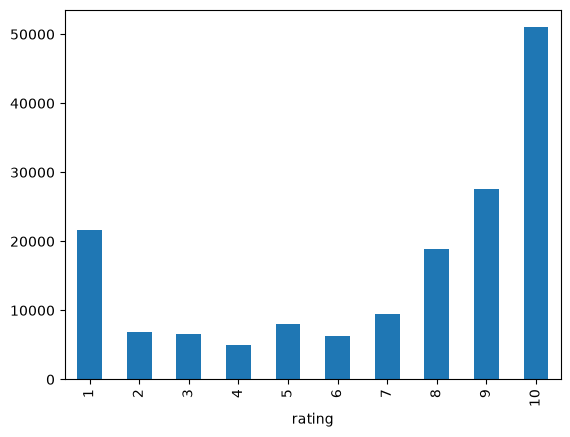

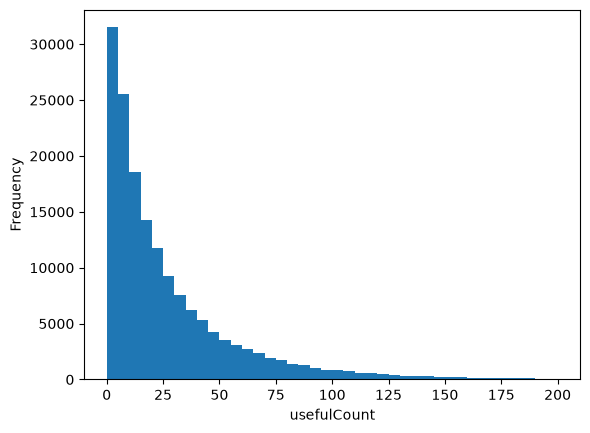

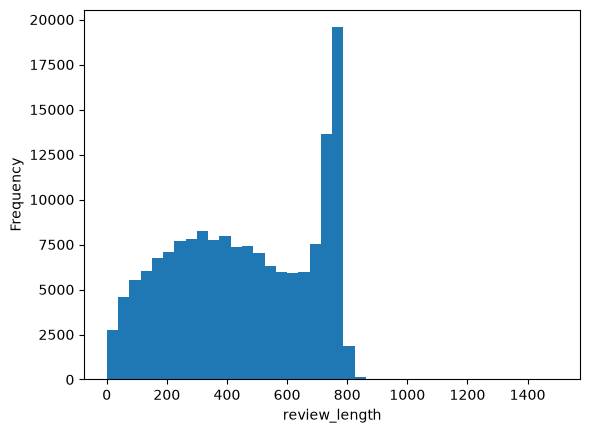

In [5]:
EDA_df.distribution_inspect()

In [6]:
EDA_df.correlation()

Data Field Correlation
+------------------+--------------------+-------------------+
|rating_usefulCount|         rating_date|   usefulCount_date|
+------------------+--------------------+-------------------+
|0.2341853750636649|-0.19623579544730904|-0.2690699925232411|
+------------------+--------------------+-------------------+



### Data Cleaning
A crucial step in the data preprocessing pipeline, aimed at improving the quality and accuracy of the dataset before analysis.
- Identifying Missing Values
- Handling Outliers
- Correcting Invalid Entries
- Removing Duplicates
- Standardizing Data: Ensure consistency in data representation.
- Transforming Variables: Apply necessary transformations to variables to enhance their interpretability or suitability for analysis.

In [7]:
import json
with open("replacement.json","r",encoding="utf-8") as f:
    replacement = json.load(f)

print("Before data cleaning:")
df_raw.show(10,truncate=80)

def data_cleaning(df: DataFrame) -> DataFrame:

    def replace_condition_and_review(df: DataFrame) -> DataFrame:
        pairs = []
        for old, new in replacement["condition"].items():
            pairs.extend((F.lit(old), F.lit(new)))
        condition_map = F.create_map(*pairs)
        df = df.withColumn(
            "condition",
            F.coalesce(condition_map[F.col("condition")], F.col("condition")),
        )

        review = F.col("review")
        for old, new in replacement["html_entities"].items():
            review = F.regexp_replace(review, old, new)
        return df.withColumn("review", review)
    
    row_count = df.count()
    df = df.dropna(subset="condition")
    print(f"After dropping rows with a null condition field\nRow count: {row_count} -> {df.count()}, removed {row_count - df.count()} rows")
    row_count = df.count()

    df = df.filter(~F.col("condition").contains("</span> users found this comment helpful"))
    print(f"After dropping rows whose condition contains '</span> users found this comment helpful'\nRow count: {row_count} -> {df.count()}, removed {row_count - df.count()} rows")
    
    # There are truncated conditions (inspired by LLM) and reviews contain HTML entities
    remaining_conditions = df.filter(F.col("condition").isin(list(replacement["condition"]))).count()
    remaining_entities = df.filter(F.col("review").rlike("&(#\\d+|[A-Za-z]+);")).count()
    print(f"Before replacement: {remaining_conditions} truncated conditions, {remaining_entities} reviews contain HTML entities")
    df = replace_condition_and_review(df)
    remaining_conditions = df.filter(F.col("condition").isin(list(replacement["condition"]))).count()
    remaining_entities = df.filter(F.col("review").rlike("&(#\\d+|[A-Za-z]+);")).count()
    print(f"After replacement: {remaining_conditions} truncated conditions, {remaining_entities} reviews contain HTML entities")
    

    df = df.withColumn(
        "review",
        F.regexp_replace(F.trim(F.regexp_replace("review",r'^"|"$',"")),r"\s+"," ")
    )

    # For duplicate reviews, keep only the row with the highest usefulCount.
    row_count = df.count()
    df_best = df.groupBy("review").agg(F.max("usefulCount").alias("usefulCount"))
    df = df.join(df_best, ["review", "usefulCount"]).dropDuplicates(["review"]).select(*df.columns)
    print(f"After keeping the row with the highest usefulCount for each review\nRow count: {row_count} -> {df.count()}, removed {row_count - df.count()} rows")

    df = df.withColumn(
        "usefulCount_log",
        F.log1p("usefulCount")
    )
    print("Added usefulCount_log = log(1 + usefulCount)")
    
    useful_stats = df.agg(
        F.lit("usefulCount").alias("column"),
        F.variance("usefulCount").alias("variance"),
        F.stddev("usefulCount").alias("stddev"),
        F.skewness("usefulCount").alias("skewness"),
    )
    useful_log_stats = df.agg(
        F.lit("usefulCount_log").alias("column"),
        F.variance("usefulCount_log").alias("variance"),
        F.stddev("usefulCount_log").alias("stddev"),
        F.skewness("usefulCount_log").alias("skewness"),
    )
    useful_stats.union(useful_log_stats).show()
    return df

def feature_engineering(df: DataFrame) -> DataFrame:
    pass

df_cleaned = data_cleaning(df_raw)
print("After data cleaning:")
df_cleaned.cache().show(10,truncate=80)
# df_cleaned.show(truncate= 80)

Before data cleaning:
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                          drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|                         Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|                        Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                            Lybrel|   

After replacement: 0 truncated conditions, 0 reviews contain HTML entities


After keeping the row with the highest usefulCount for each review
Row count: 159498 -> 111196, removed 48302 rows
Added usefulCount_log = log(1 + usefulCount)


+---------------+------------------+------------------+-------------------+
|         column|          variance|            stddev|           skewness|
+---------------+------------------+------------------+-------------------+
|    usefulCount|1280.8439904886332| 35.78888082196247|  4.488371797025284|
|usefulCount_log|1.4185723965101835|1.1910383690335855|-0.2966022927458237|
+---------------+------------------+------------------+-------------------+

After data cleaning:


+--------+---------------+----------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+
|uniqueID|       drugName|       condition|                                                                          review|rating|      date|usefulCount|   usefulCount_log|
+--------+---------------+----------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+
|    4884|         Belviq|     Weight Loss|            225lbs down to 180lbs in less than a year. No negative side effects.|    10|2014-12-20|        181| 5.204006687076795|
|  185195|        Harvoni|     Hepatitis C|3 weeks 3 days in. Had blood work done waiting on first check. Hep for almost...|     8|2015-10-09|         39|3.6888794541139363|
|   13848|       Bydureon|Diabetes, Type 2|4 injections so far and experienced the nausea which initially lasted three d...|     8